How the linear Regressions is done.
   
. Understand the problem.  y = mx + b

1. Step 1 Calculate the required values
   To calculate \(m\) and \(b\), we need these five values:
- \(n\) = number of data points
- \(\sum x\) = sum of all \(x\) values
- \(\sum y\) = sum of all \(y\) values
- \(\sum x^2\) = sum of squared \(x\) values
- \(\sum xy\) = sum of the products of corresponding \(x\) and \(y\) values


3.   Step 2 — Calculate the slope \(m\)
4.   Step 3 — Calculate the intercept \(b\)

1.   Step 4 — Put \(m\) and \(b\) into the equation
2.   Step 5 — Use the equation to make predictions



m and b is calculated now we will calculate the  and loss function


Implementationn of Linear Regression

# New Section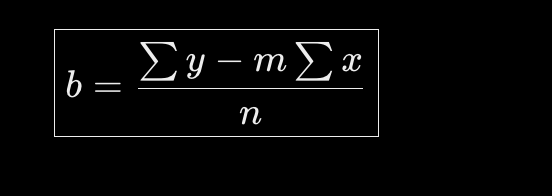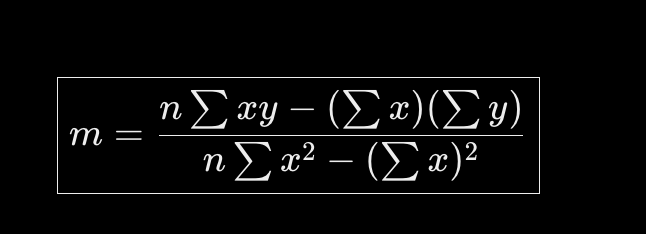

In [2]:

import numpy as np
import pandas as pd

class LinearRegressionCustom:
    def fit(self, X, y):
        X = np.array(X).flatten()
        y = np.array(y)

        n = len(X)

        # Calculate slope (m)
        self.m = (
            (n * np.sum(X * y)) - (np.sum(X) * np.sum(y))
        ) / (
            (n * np.sum(X ** 2)) - (np.sum(X) ** 2)
        )

        # Calculate intercept (b)
        self.b = (np.sum(y) - self.m * np.sum(X)) / n

    def predict(self, X):
        X = np.array(X)
        return self.m * X + self.b


In [3]:
from sklearn.model_selection import train_test_split
import pandas as pd


df= pd.read_csv('/content/placement.csv')
df

,cgpa,placement_exam_marks,placed
0,7.19,26.0,1
1,7.46,38.0,1
2,7.54,40.0,1
3,6.42,8.0,1
4,7.23,17.0,0
...,...,...,...
995,8.87,44.0,1
996,9.12,65.0,1
997,4.89,34.0,0
998,8.62,46.0,1


In [4]:

X = df.drop(columns=["placed"]).to_numpy()
X = X[:, 0]
y = df["placed"].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [5]:
print("X shape:", np.array(X).shape)
print("y shape:", np.array(y).shape)

print("X length:", len(X))
print("y length:", len(y))

X shape: (1000,)
y shape: (1000,)
X length: 1000
y length: 1000


In [6]:
model = LinearRegressionCustom()

model.fit(X_train, y_train)

print("Slope (m):", model.m)
print("Intercept (b):", model.b)

y_pred = model.predict(X_test)

print("Prediction:", model.predict([5]))

print("Actual:", y_test)
print("Predicted:", y_pred)



Slope (m): 0.010470845673104604
Intercept (b): 0.422192676124489
Prediction: [0.4745469]
Actual: [1 1 1 1 0 1 1 0 0 0 0 0 1 1 0 1 0 1 0 0 1 1 0 0 1 1 1 1 1 0 0 1 1 0 1 1 0
 1 1 1 1 1 1 0 1 1 1 1 1 0 0 0 1 0 0 0 0 1 1 0 0 1 0 0 1 0 1 0 1 0 0 0 1 0
 0 1 1 0 0 1 0 1 0 1 0 1 1 1 0 0 0 0 1 0 0 0 1 0 0 0 1 0 0 1 0 1 1 1 1 0 1
 0 0 1 1 1 0 0 1 0 1 0 0 1 1 1 0 0 0 0 0 1 0 1 0 0 1 0 1 0 0 0 0 1 1 0 1 0
 1 0 0 0 0 0 0 1 1 1 1 1 1 0 1 0 0 0 0 0 1 0 1 0 0 0 1 0 0 0 0 0 0 1 1 0 0
 0 1 0 0 1 0 0 1 1 1 1 0 1 1 0]
Predicted: [0.48208591 0.49046259 0.48721663 0.48470362 0.48543658 0.4918238
 0.50208523 0.48952021 0.49046259 0.49842043 0.50637828 0.50962424
 0.48910138 0.48606483 0.48784488 0.50198052 0.49150967 0.50575002
 0.50616886 0.50103814 0.49936281 0.49873456 0.48397067 0.5030276
 0.49109084 0.49758276 0.49004376 0.49643097 0.49580272 0.49014846
 0.49873456 0.50690182 0.50438881 0.48941551 0.4818765  0.50899599
 0.49349914 0.49098613 0.49653568 0.50281819 0.49967693 0.49643097
 0.49569801 0.4894

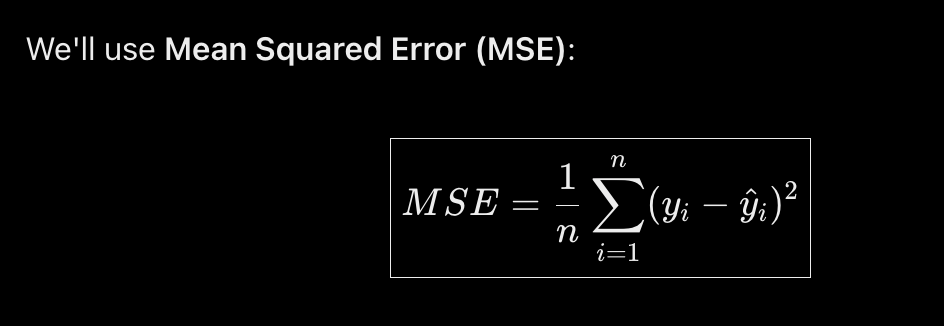



*   Where:
- \(yi\) = actual value
- \(yi\) = predicted value
- \(n\) = number of data points
- \(MSE\) = average squared prediction error

# Implementing the Loss Function

In [7]:
import numpy as np
def mse(y_actual, y_predicted):
    return np.mean((np.array(y_actual) - np.array(y_predicted)) ** 2)

In [8]:
y_test

y_test

array([1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 1, 1,
       0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0,
       1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0,
       1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1,
       0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0,
       1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 1,
       0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0,
       0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1,
       1, 0])

In [9]:
# Lets Test the Loss funnction
#first parameter is of actual and second is of predicted

loss = mse(y_test,y_pred)


print("Predictions:", y_pred)
print("Loss Found by MSE",loss)

Predictions: [0.48208591 0.49046259 0.48721663 0.48470362 0.48543658 0.4918238
 0.50208523 0.48952021 0.49046259 0.49842043 0.50637828 0.50962424
 0.48910138 0.48606483 0.48784488 0.50198052 0.49150967 0.50575002
 0.50616886 0.50103814 0.49936281 0.49873456 0.48397067 0.5030276
 0.49109084 0.49758276 0.49004376 0.49643097 0.49580272 0.49014846
 0.49873456 0.50690182 0.50438881 0.48941551 0.4818765  0.50899599
 0.49349914 0.49098613 0.49653568 0.50281819 0.49967693 0.49643097
 0.49569801 0.48941551 0.49287088 0.48972963 0.49391797 0.4943368
 0.49203322 0.4918238  0.49590743 0.49370855 0.49726864 0.50093344
 0.48554129 0.50030518 0.49632626 0.49360384 0.49318501 0.48784488
 0.49538389 0.5103572  0.49611685 0.49423209 0.4943368  0.49496505
 0.49946752 0.49852514 0.49527918 0.5005146  0.49883927 0.49339443
 0.49213793 0.50156169 0.483133   0.49266147 0.5017711  0.49810631
 0.49130026 0.50040989 0.49234734 0.49203322 0.50627357 0.50637828
 0.49276618 0.5005146  0.51245137 0.49611685 0.49412

In [42]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss
)

# Get numerical predictions from Linear Regression
y_pred_values = np.asarray(model.predict(X_test)).flatten()

# Convert numerical predictions into binary classes
y_pred = (y_pred_values >= 0.5).astype(int)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1-score:", f1_score(y_test, y_pred, zero_division=0))

Accuracy: 0.55
Precision: 0.5172413793103449
Recall: 0.4838709677419355
F1-score: 0.5


# Gradient Descent from Scratch


*   Step A: Calculate predictions
*   Step B: Calculate the initial loss

* Step C: Calculate the gradients
  A gradient tells us how the loss changes when we change a parameter.

We need two gradients:
- \(\frac{\partial MSE}{\partial m}\): how the loss changes with the slope.
- \(\frac{\partial MSE}{\partial b}\): how the loss changes with the intercept.

4. Step D: Update \(m\) and \(b\)

Implementing. the gradient Descent

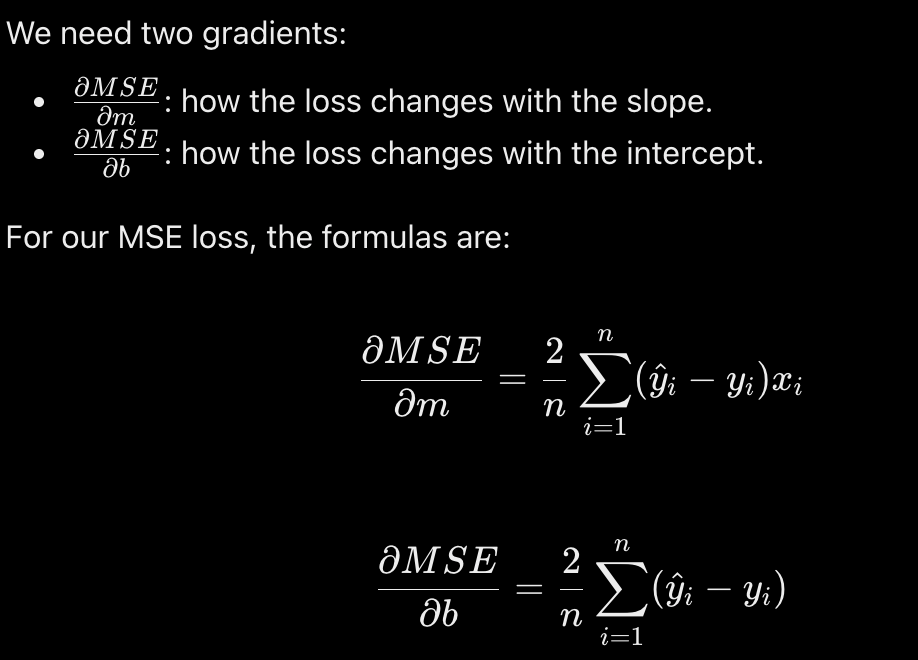

In [43]:

import numpy as np

class LinearRegressionCustom2:
    def fit(self, X, y, epochs=1000, learning_rate=0.01):
        X = np.asarray(X, dtype=float).reshape(-1)
        y = np.asarray(y, dtype=float).reshape(-1)

        if len(X) != len(y):
            raise ValueError("X and y must have the same number of samples")

        self.m = 0.0
        self.b = 0.0
        n = len(X)
        self.loss_history = []

        for _ in range(epochs):
            y_pred = self.m * X + self.b

            dm = (2 / n) * np.sum((y_pred - y) * X)
            db = (2 / n) * np.sum(y_pred - y)

     # New Parameter = old parameter - @(gradient)

            self.m = self.m - learning_rate * dm
            self.b = self.b - learning_rate * db

            # Record loss after updating parameters
            y_pred = self.m * X + self.b
            self.loss_history.append(np.mean((y - y_pred) ** 2))

        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float).reshape(-1)
        return self.m * X + self.b

    def loss(self, y, y_pred):
        y = np.asarray(y, dtype=float).reshape(-1)
        y_pred = np.asarray(y_pred, dtype=float).reshape(-1)
        return np.mean((y - y_pred) ** 2)


In [44]:
model = LinearRegressionCustom2()

model.fit(X_train, y_train, learning_rate=0.001, epochs=1000)

train_pred = model.predict(X_train)
test_pred = model.predict(X_test)

print("Slope:", model.m)
print("Intercept:", model.b)
print("Training Loss:", model.loss(y_train, train_pred))
print("Testing Loss:", model.loss(y_test, test_pred))

print("First 5 epoch losses:", model.loss_history[:5])
print("Last 5 epoch losses:", model.loss_history[-5:])

Slope: 0.0684510600573918
Intercept: 0.016004744938094492
Training Loss: 0.2511909434442419
Testing Loss: 0.24783890792438953
First 5 epoch losses: [np.float64(0.44893585163454774), np.float64(0.4115761941935932), np.float64(0.381276186113643), np.float64(0.3567018028327748), np.float64(0.336771103347484)]
Last 5 epoch losses: [np.float64(0.2511910935329823), np.float64(0.2511910560091167), np.float64(0.2511910184863715), np.float64(0.25119098096474657), np.float64(0.2511909434442419)]


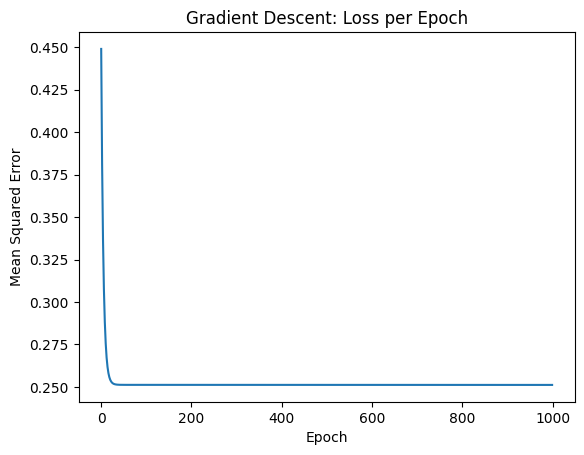

In [45]:
import matplotlib.pyplot as plt

plt.plot(model.loss_history)
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Gradient Descent: Loss per Epoch")
plt.show()

[[65 42]
 [48 45]]


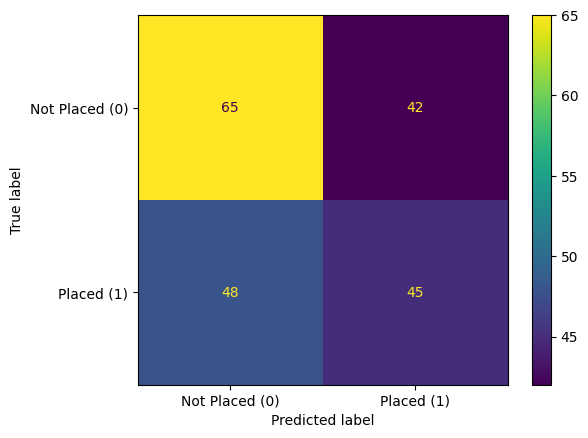

In [46]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# 1. Predict using your custom Linear Regression model
y_pred_values = model.predict(X_test)

# 2. Convert numerical predictions into 0 or 1
y_pred = (y_pred_values >= 0.5).astype(int)

# 3. Generate confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print(cm)

# 4. Plot confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Placed (0)", "Placed (1)"]
)

disp.plot()
plt.show()

In [47]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss
)

# Get numerical predictions from Linear Regression
y_pred_values = np.asarray(model.predict(X_test)).flatten()

# Convert numerical predictions into binary classes
y_pred = (y_pred_values >= 0.5).astype(int)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1-score:", f1_score(y_test, y_pred, zero_division=0))

Accuracy: 0.55
Precision: 0.5172413793103449
Recall: 0.4838709677419355
F1-score: 0.5


In [48]:
cf = LinearRegressionCustom();  cf.fit(X_train, y_train)
gd = LinearRegressionCustom2(); gd.fit(X_train, y_train, learning_rate=0.001, epochs=1000)
for name, m in [("closed-form", cf), ("gradient descent", gd)]:
    pred = (np.asarray(m.predict(X_test)).ravel() >= 0.5).astype(int)
    print(name, accuracy_score(y_test, pred), pred.sum())

closed-form 0.525 48
gradient descent 0.55 87


In [50]:
# scale the feature so GD converges
mu, sd = X_train.mean(), X_train.std()
Xtr, Xte = (X_train - mu) / sd, (X_test - mu) / sd

gd = LinearRegressionCustom2().fit(Xtr, y_train, learning_rate=0.1, epochs=1000)

In [51]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

X2 = df[["cgpa", "placement_exam_marks"]].to_numpy()
Xtr, Xte, ytr, yte = train_test_split(X2, y, test_size=0.2, random_state=42)
sc = StandardScaler().fit(Xtr)
clf = LogisticRegression().fit(sc.transform(Xtr), ytr)
print(accuracy_score(yte, clf.predict(sc.transform(Xte))))

0.535
